In [8]:
import numpy as np
import matplotlib.pyplot as plt
import function as fn

# 1. Configuração dos arquivos

INPUT_FILE = "foto1.jpeg"
OUTPUT_GRAY_FILE = "foto1Cinza.png"


In [9]:

# 2. Conversão RGB para YCrCb

matrizBase = np.array([
    [ 0.299000,  0.587000,  0.114000],
    [ 0.500000, -0.418688, -0.081312],
    [-0.168736, -0.331264,  0.500000]
], dtype=np.float64)

deslocamento = np.array([0, 128, 128], dtype=np.float64)

ycrcb = fn.rgb_to_ycrcb(
    INPUT_FILE,
    OUTPUT_GRAY_FILE,
    matrizBase,
    deslocamento
)

# 3. Aplicação da DCT 2D

F_blocos, blocos, Y, numBlocosAltura, numBlocosLargura, altura, largura = (
    fn.apply_dct(ycrcb, 8)
)

print("\nDimensões dos blocos transformados:", F_blocos.shape)

# 4. Matriz de quantização

Q = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float64)

print("\nMatriz de quantização (Q):")
print(Q)


Dimensões da imagem: (4344, 7728, 3)
Tipo dos dados: float64
Primeiro pixel de YCrCb: [111.012    132.984288 103.162528]
primeiro pixel da imagem deslocada: -16.988
Dimensões originais: (4344, 7728)
Linhas a adicionar: 0
Colunas a adicionar: 0
Dimensões após o padding: (4344, 7728)
Quantidade de blocos na vertical: 543
Quantidade de blocos na horizontal: 966
Formato da matriz de blocos: (543, 966, 8, 8)
Primeiro bloco 8x8:
[[-16.988 -18.988 -19.988 -21.988 -21.988 -19.988 -18.988 -16.988]
 [-18.988 -19.988 -20.988 -21.988 -21.988 -20.988 -19.988 -18.988]
 [-19.988 -19.988 -21.988 -21.988 -21.988 -21.988 -19.988 -19.988]
 [-18.988 -19.988 -20.988 -20.988 -20.988 -20.988 -19.988 -18.988]
 [-17.988 -18.988 -18.988 -18.988 -18.988 -18.988 -18.988 -17.988]
 [-17.988 -17.988 -17.988 -17.988 -17.988 -17.988 -17.988 -17.988]
 [-18.988 -18.988 -17.988 -17.988 -17.988 -17.988 -18.988 -18.988]
 [-19.988 -19.988 -18.988 -18.988 -18.988 -18.988 -19.988 -19.988]]
Matriz da DCT (C):
[[ 0.35355339  0.

In [3]:
# 5. Execução para diferentes fatores de escala

S = [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8]

resultados = []

for s_atual in  S:

    print(f"\n{'=' * 50}")
    print(f"Executando para s = {s_atual}")
    print(f"{'=' * 50}")

    arquivo_saida = f"foto1Processada_s_{s_atual}.png"

    # Executa a compressão, a reconstrução e as métricas
    resultado = fn.executar_jpeg_like(
        F_blocos=F_blocos,
        Q=Q,
        s=s_atual,
        Y=Y,
        heightBlocks=numBlocosAltura,
        widthBlocks=numBlocosLargura,
        height=altura,
        width=largura,
        output=arquivo_saida
    )

    resultados.append(resultado)

    # Resultados da configuração atual
    print(f"BPP: {resultado['bpp']:.4f}")
    print(f"Coeficientes zerados: {resultado['percentualZero']:.2f}%")
    print(f"MSE: {resultado['MSE']:.4f}")
    print(f"PSNR: {resultado['PSNR']:.4f} dB")
    print(f"SSIM: {resultado['SSIM']:.4f}")
    print(f"Imagem salva em: {arquivo_saida}")

# 6. Tabela comparativa

print("\n\nRESUMO DOS RESULTADOS")
print("-" * 65)

print(
    f"{'s':>6} | {'BPP':>10} | {'Zeros (%)':>12} | "
    f"{'PSNR (dB)':>12} | {'SSIM':>10}"
)

print("-" * 65)

for r in resultados:
    print(
        f"{r['s']:>6} | "
        f"{r['bpp']:>10.4f} | "
        f"{r['percentualZero']:>12.2f} | "
        f"{r['PSNR']:>12.4f} | "
        f"{r['SSIM']:>10.4f}"
    )



Executando para s = 0.25
Coeficientes desquantizados do primeiro bloco:
[[-156.    0.    5.    0.    0.    0.    0.    0.]
 [  -6.    0.    7.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.]
 [   7.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.]]
BPP: 3.2064
Coeficientes zerados: 87.16%
MSE: 0.3991
PSNR: 52.1205 dB
SSIM: 0.9965
Imagem salva em: foto1Processada_s_0.25.png

Executando para s = 0.5
Coeficientes desquantizados do primeiro bloco:
[[-152.    0.    5.    0.    0.    0.    0.    0.]
 [  -6.    0.    7.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.]
 [   7.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.

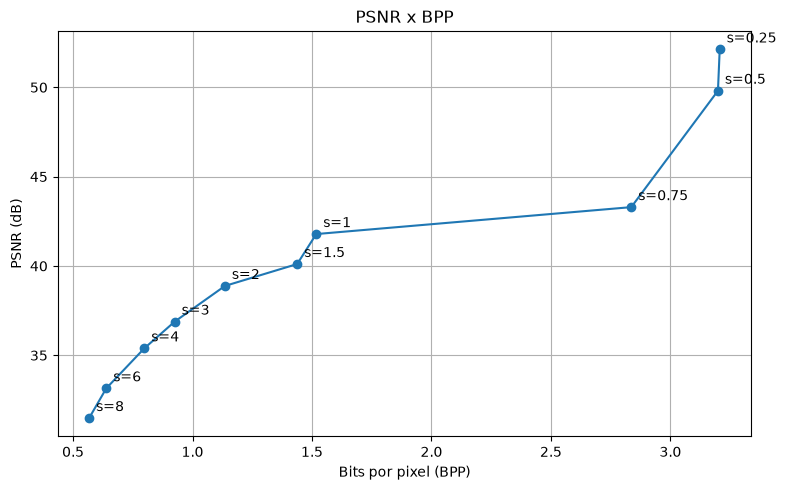

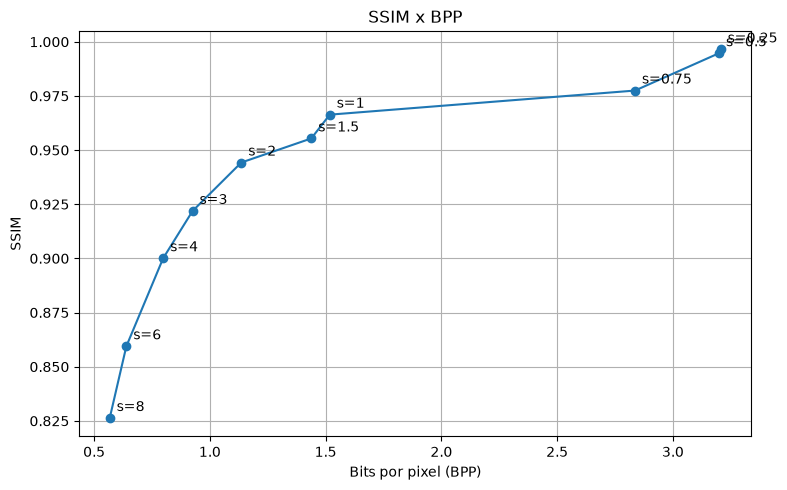

In [4]:
# 7. Curva qualidade x compressão

bpp = [r["bpp"] for r in resultados]
psnr = [r["PSNR"] for r in resultados]
ssim = [r["SSIM"] for r in resultados]

# 7.1 PSNR x BPP
plt.figure(figsize=(8, 5))
plt.plot(bpp, psnr, marker="o")

for r in resultados:
    plt.annotate(
        f"s={r['s']}",
        (r["bpp"], r["PSNR"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Bits por pixel (BPP)")
plt.ylabel("PSNR (dB)")
plt.title("PSNR x BPP")
plt.grid(True)
plt.tight_layout()
plt.show()

# 7.2 SSIM x BPP
plt.figure(figsize=(8, 5))
plt.plot(bpp, ssim, marker="o")

for r in resultados:
    plt.annotate(
        f"s={r['s']}",
        (r["bpp"], r["SSIM"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Bits por pixel (BPP)")
plt.ylabel("SSIM")
plt.title("SSIM x BPP")
plt.grid(True)
plt.tight_layout()
plt.show()


In [5]:

# 9 DCT rápida por biblioteca
# 9.1 Validação numérica

import numpy as np
from scipy.fft import dctn, idctn

# Selecionar um bloco 8x8
bloco = blocos[0, 0].astype(np.float64)

# DCT matricial
C = fn.matrix_dct(8)
F_matriz = C @ bloco @ C.T

# DCT rápida da biblioteca SciPy
F_fast = dctn(bloco, type=2, norm="ortho")

# Erro máximo entre os coeficientes
erro_maximo = np.max(np.abs(F_matriz - F_fast))

print("Erro máximo entre as DCTs:", f"{erro_maximo:.12e}")
print("DCTs numericamente equivalentes:",
      np.allclose(F_matriz, F_fast, atol=1e-10))

# Reconstrução pela versão matricial
bloco_rec_matriz = C.T @ F_matriz @ C

# Reconstrução pela versão SciPy
bloco_rec_fast = idctn(F_fast, type=2, norm="ortho")

# Erro máximo de reconstrução
erro_rec_matriz = np.max(np.abs(bloco - bloco_rec_matriz))
erro_rec_fast = np.max(np.abs(bloco - bloco_rec_fast))

print("Erro da reconstrução matricial:",
      f"{erro_rec_matriz:.12e}")
print("Erro da reconstrução SciPy:    ",
      f"{erro_rec_fast:.12e}")

# Comparar as duas reconstruções
print("Reconstruções numericamente equivalentes:",
      np.allclose(bloco_rec_matriz, bloco_rec_fast, atol=1e-10))


Erro máximo entre as DCTs: 1.803925768707e-13
DCTs numericamente equivalentes: True
Erro da reconstrução matricial: 9.592326932761e-14
Erro da reconstrução SciPy:     1.421085471520e-14
Reconstruções numericamente equivalentes: True


In [ ]:

# 10 Comparação de desempenho das DCTs

import time

bloco = blocos[0, 0].astype(np.float64)

# Preparar a matriz fora da medição
C = fn.matrix_dct(8)

# Exeutar somente a DCT
def dct_matricial(bloco):
    return C @ bloco @ C.T

def dct_scipy(bloco):
    return dctn(bloco, type=2, norm="ortho")

# Parâmetros de teste
repeticoes = 10
iteracoes = 1000

tempos_matricial = []
tempos_scipy = []

# Medir a DCT matricial
for _ in range(repeticoes):
    inicio = time.perf_counter()

    for _ in range(iteracoes):
        dct_matricial(bloco)

    fim = time.perf_counter()
    tempos_matricial.append((fim - inicio) / iteracoes)

# Medir a DCT rápida do SciPy
for _ in range(repeticoes):
    inicio = time.perf_counter()

    for _ in range(iteracoes):
        dct_scipy(bloco)

    fim = time.perf_counter()
    tempos_scipy.append((fim - inicio) / iteracoes)

# Mediana do tempo por execução, em segundos
tempo_matricial = np.median(tempos_matricial)
tempo_scipy = np.median(tempos_scipy)

# Converter para microssegundos
tempo_matricial_us = tempo_matricial * 1e6
tempo_scipy_us = tempo_scipy * 1e6

speedup = tempo_matricial / tempo_scipy

print(f"Tempo médio por DCT matricial: {tempo_matricial_us:.3f} µs")
print(f"Tempo médio por DCT SciPy:     {tempo_scipy_us:.3f} µs")
print(f"Speedup: {speedup:.2f}x")

if speedup > 1:
    print("A versão SciPy foi mais rápida.")
elif speedup < 1:
    print("A versão matricial foi mais rápida.")
else:
    print("As duas versões apresentaram tempos semelhantes.")


Tempo médio por DCT matricial: 3.270 µs
Tempo médio por DCT SciPy:     17.202 µs
Speedup: 0.19x
A versão matricial foi mais rápida.
